In [1]:
import sys
import os
import json
import numpy as np
import pandas as pd
from datetime import datetime
import shutil
import pathlib
from pathlib import Path
from matplotlib import pyplot as plt
import h5py
import subprocess

from snudda import SnuddaInit
from snudda import SnuddaPlace
from snudda import SnuddaDetect
from snudda import SnuddaPrune
from snudda.utils.load import SnuddaLoad
from snudda import Snudda
from snudda.input import SnuddaInput

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return json.JSONEncoder.default(self, obj)

def update_nmda_ratio(syn_config, ratio):
    with open(syn_config, "r") as f:
        config = json.load(f)
    config["1"]["synapse"]["nmda_ratio"] = ratio

    with open(syn_config, "w") as f:
        json.dump(config, f, indent=4)

def run_nmda_VC(snudda_data_path, rds, ratio,
                nmda_config, hold_v, flag, simulation_time, act_time, number_neurons, neuron_path, num_inputs):

    if act_time + 0.2 >= simulation_time:
        raise ValueError("Simulation must continue at least 200 ms after stimulation.")

    neuron_name = os.path.basename(neuron_path)
    update_nmda_ratio(nmda_config, ratio)
    network_path = os.path.join(os.getcwd(), "network", f"test_{flag}_{ratio}_{neuron_name}_{num_inputs}")
    # ============================================================
    # 1. Create network containing one neuron
    # ============================================================
    ss = Snudda(network_path=str(network_path))

    ss.init_tiny(
        neuron_paths=[str(neuron_path)],
        snudda_data=snudda_data_path,
        neuron_names=["dSPN"],
        number_of_neurons=[number_neurons],
        random_seed=rds
    )

    ss.create_network()

    sl = SnuddaLoad(os.path.join(network_path, "network-neuron-positions.hdf5"))
    neurons = sl.data["neurons"]
    neuron_ids = [int(n["neuron_id"]) for n in neurons]

    csv_path = os.path.join(network_path, "input.csv")
    base_seq = act_time
    data = np.tile(base_seq, (num_inputs, 1))
    pd.DataFrame(data).to_csv(csv_path, index=False, header=False)

    config = {
        "generator": "csv",
        "csv_file": csv_path,
        "type": "AMPA_NMDA",
        "conductance": 5e-10,
        "mod_file": "tmGlut",
        "synapse_density": "1.15*0.05/(1+exp(-(d-30e-6)/5e-6))",
        "parameter_file": nmda_config,
        "num_inputs": num_inputs,
    }

    input_file = os.path.join(network_path, "input.json")
    input_data = {str(nid): {"cortical_act": config} for nid in neuron_ids}

    with open(input_file, "w", encoding="utf-8") as f:
        json.dump(input_data, f, indent=4)

    SnuddaInput(
        network_path=network_path,
        snudda_data=snudda_data_path,
        use_meta_input=False,
        input_config_file=input_file,
        verbose=False,
        random_seed=rds,
        time=simulation_time,
    ).generate()

    spike_data_path = os.path.join(network_path, "input-spikes.hdf5")

    sim_config = {
        "network_path": network_path,
        "time": simulation_time,
        "input_file": spike_data_path
    }

    volt_clamp_info = {}
    for p in neuron_ids:
        volt_clamp_info[str(p)] = {
            "voltage": hold_v,
            "duration": simulation_time,
            "save_current": True
        }

    sim_config["voltage_clamp"] = volt_clamp_info

    simulation_config_file = os.path.join(network_path, "simulation-config.json")
    print(f"Writing simulation config: {simulation_config_file}")

    with open(simulation_config_file, "w") as f:
        json.dump(sim_config, f, indent=4, cls=NumpyEncoder)

    cmd = [
        "mpirun", "-n", "3", "snudda", "simulate",
        network_path, "--simulation_config", simulation_config_file
    ]

    print(" ".join(cmd))
    subprocess.run(cmd, check=True)

    return network_path


def collect_amp_data(network_path, flag, t_stimulate, output_path,neuron_path, ratio, num_inputs, show_plot=False):
    sl = SnuddaLoad(os.path.join(network_path, "network-neuron-positions.hdf5"))
    neurons = sl.data["neurons"]
    neuron_ids = [int(n["neuron_id"]) for n in neurons]
    fpath = os.path.join(network_path, "simulation", "output.hdf5")
    neuron_name = os.path.basename(neuron_path)
    output_fig_path = os.path.join(output_path, f"PSC_{flag}_{neuron_name}_{ratio}_{num_inputs}.jpg")

    dt = 0.025
    t_stimulate = t_stimulate * 1000  # Convert to ms

    # Baseline before stimulation
    t_s_base_ms, t_e_base_ms = t_stimulate - 100, t_stimulate - 20

    # Plotting window
    t_s_ms, t_e_ms = t_stimulate - 25, t_stimulate + 300

    t_s_base, t_e_base = int(t_s_base_ms / dt), int(t_e_base_ms / dt)
    t_s, t_e = int(t_s_ms / dt), int(t_e_ms / dt)

    # AMPA peak window
    t_ampa_s = int(t_stimulate / dt)
    t_ampa_e = int((t_stimulate + 20) / dt)

    # NMDA window: 50–60 ms after stimulation
    window_index_s = int((t_stimulate + 50) / dt)
    window_index_e = int((t_stimulate + 60) / dt)

    amp_list = {}
    preserve_id = []
    with h5py.File(fpath, "r") as f:
        for p in neuron_ids:
            epsc = f["neurons"][str(p)]["current"][0] * 1e12
            baseline = np.mean(epsc[t_s_base:t_e_base])
            epsc_subtract = epsc - baseline

            if flag == "ampa":
                amp = abs(np.min(epsc_subtract[t_ampa_s:t_ampa_e]))
            elif flag == "nmda":
                amp = np.mean(epsc_subtract[window_index_s:window_index_e])
            else:
                raise ValueError("flag must be 'ampa' or 'nmda'")
            if amp>=0:
                amp_list[p] = amp
                preserve_id.append(p)

            if show_plot:
                time = np.arange(len(epsc)) * dt
                print(f"Plotting PSC for post-synaptic neuron {p}")
                plt.plot(time[t_s:t_e], epsc_subtract[t_s:t_e], c='k')
                if p not in preserve_id:
                    plt.plot(time[t_s:t_e], epsc_subtract[t_s:t_e], c='orange')

    if show_plot:
        plt.axvline(t_stimulate, color="red", linestyle="--", label="Stimulus")

        if flag == "nmda":
            plt.axvspan(t_stimulate + 50, t_stimulate + 60,
                        color="orange", alpha=0.2, label="NMDA window")

        plt.xlabel("Time (ms)")
        plt.ylabel("PSC (pA)")
        plt.legend()
        plt.grid()
        plt.savefig(output_fig_path, dpi=300)
        plt.show()

    return amp_list,preserve_id



Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Region Cube uses random seed 2240790599
Generating 179 points for /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/mesh/Cube-cube-mesh-4.6319589535986436e-05.obj
Filtering, keeping inside points: 14 

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 56.4s

Execution time: 56.4s

Execution time: 56.4s
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Region Cube uses random seed 2240790599
Generating 179 points for /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_0.3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/mesh/Cube-cube-

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 160.8s

Execution time: 160.8s

Execution time: 160.8s
Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


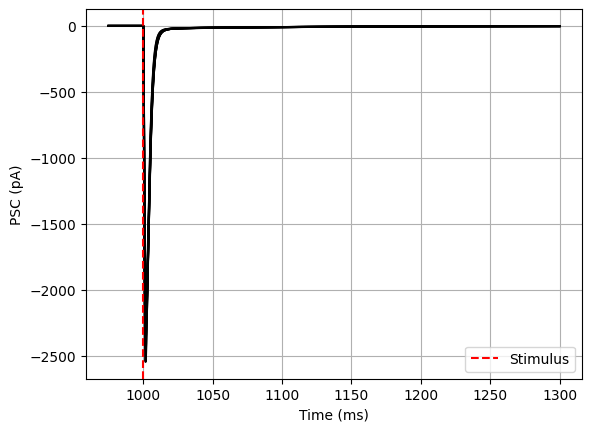

Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


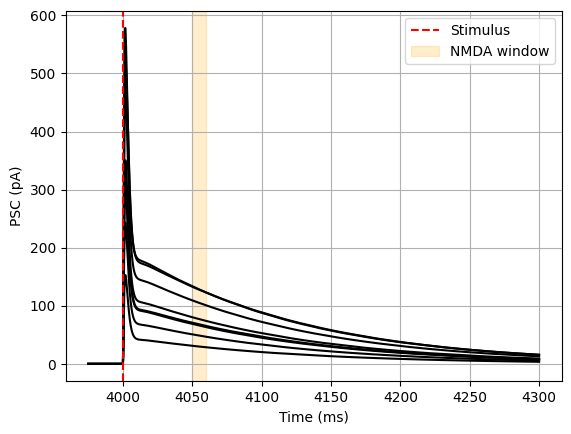

NMDA/AMPA ratio for 8 neurons: 0.035119989091055466 ± 0.013337653717544787
Creating missing directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Created directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 67.5s

Execution time: 67.5s

Execution time: 67.5s
Creating missing directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Created directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_1_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_distri

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 186.4s

Execution time: 186.4s

Execution time: 186.4s
Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


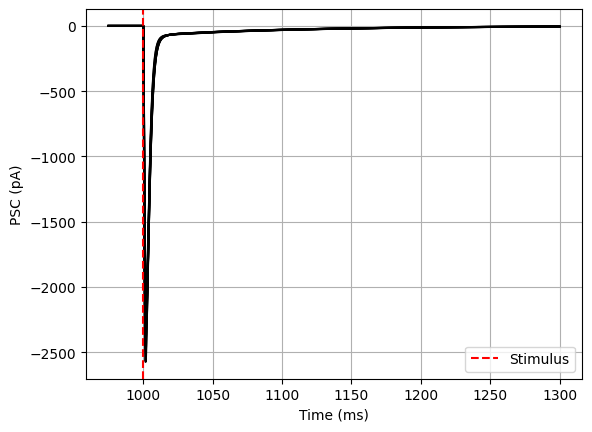

Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


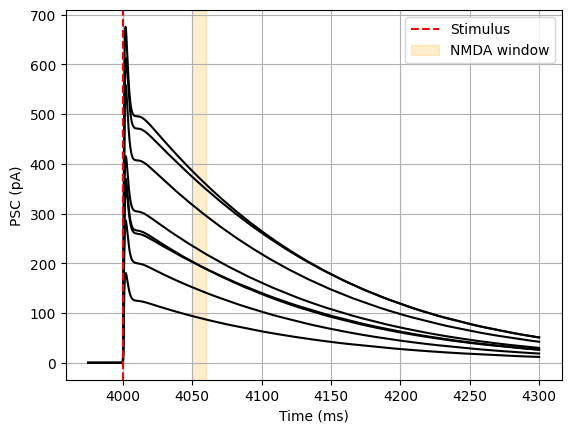

NMDA/AMPA ratio for 8 neurons: 0.1010778165344803 ± 0.0368179216667661
Creating missing directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Created directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_dist

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 67.4s

Execution time: 67.4s

Execution time: 67.4s
Creating missing directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Created directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_3_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_distri

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 178.2s

Execution time: 178.2s

Execution time: 178.2s
Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


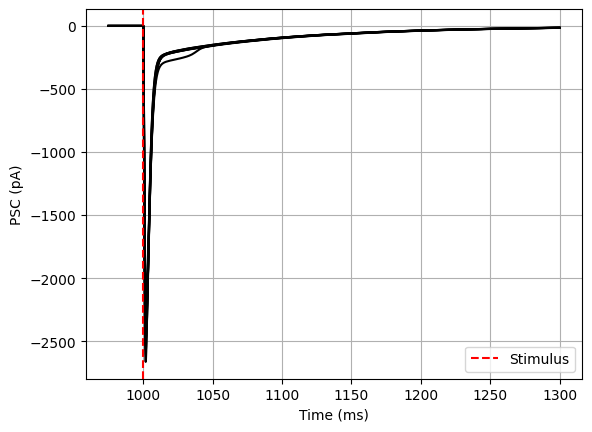

Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


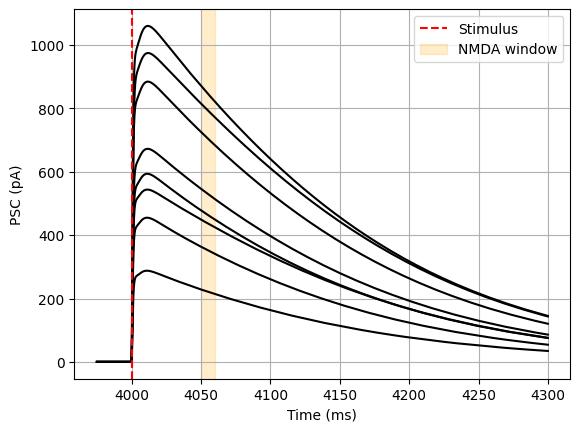

NMDA/AMPA ratio for 8 neurons: 0.2234381012928816 ± 0.07646636277883638
Creating missing directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Created directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_dis

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 59.4s

Execution time: 59.4s

Execution time: 59.4s
Creating missing directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Created directory /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/log
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_4_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_distri

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 162.3s

Execution time: 162.3s

Execution time: 162.3s
Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


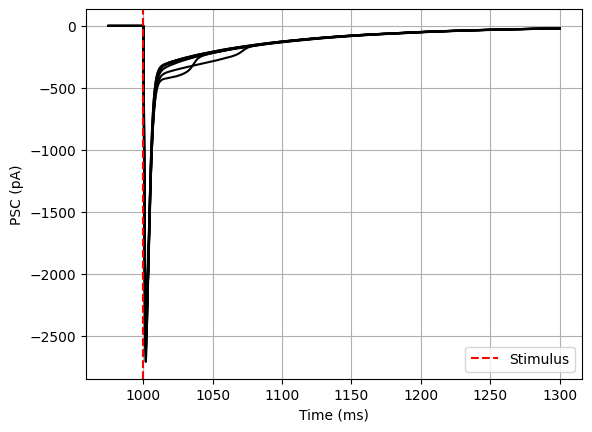

Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


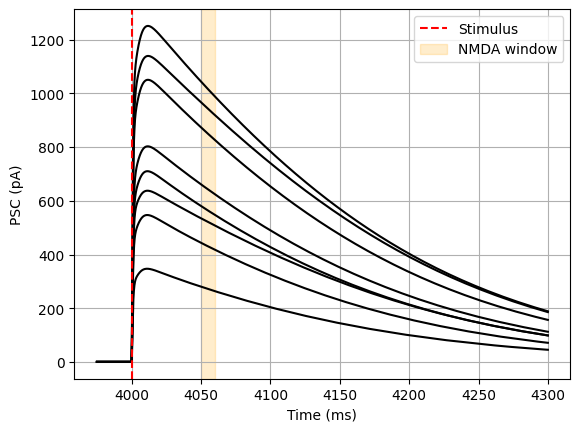

NMDA/AMPA ratio for 8 neurons: 0.26413050794898796 ± 0.08876911460133695
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Region Cube uses random seed 2240790599
Generating 179 points for /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_ampa_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/mesh/Cube-cube-mesh

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 60.8s

Execution time: 60.9s

Execution time: 60.9s
Adding neurons: dSPN from dir /Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620
Writing /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Placing neurons
Network path: /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100
Reading SNUDDA_DATA=/Users/peirui/code_collection/BasalGangliaData/data from /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/network-config.json
Region Cube uses random seed 2240790599
Generating 179 points for /Users/peirui/code_collection/treem/tutorials/syn_distribution/network/test_nmda_5_str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620_100/mesh/Cube-cube-mesh-4.6

/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/core.py:804: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set reset_random123=True to ensure reproducible Random123 streams.
  sim.clear_neuron()
/Users/peirui/code_collection/Snudda/snudda/simulate/simulate.py:3457: UserWarning: clear_neuron() called with reset_random123=False. If you plan to run another simulation in the same process, set re


Execution time: 117.6s

Execution time: 117.6s

Execution time: 117.6s
Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


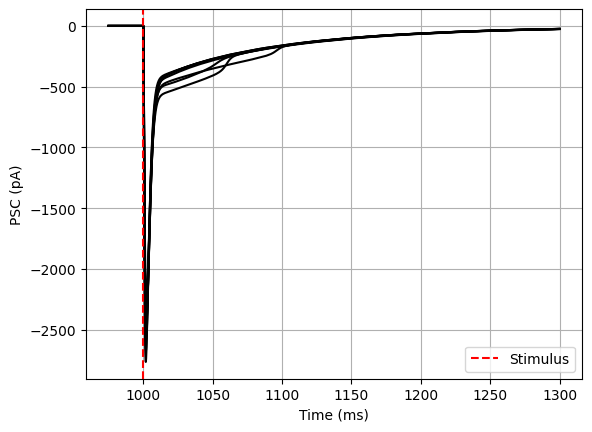

Plotting PSC for post-synaptic neuron 0
Plotting PSC for post-synaptic neuron 1
Plotting PSC for post-synaptic neuron 2
Plotting PSC for post-synaptic neuron 3
Plotting PSC for post-synaptic neuron 4
Plotting PSC for post-synaptic neuron 5
Plotting PSC for post-synaptic neuron 6
Plotting PSC for post-synaptic neuron 7


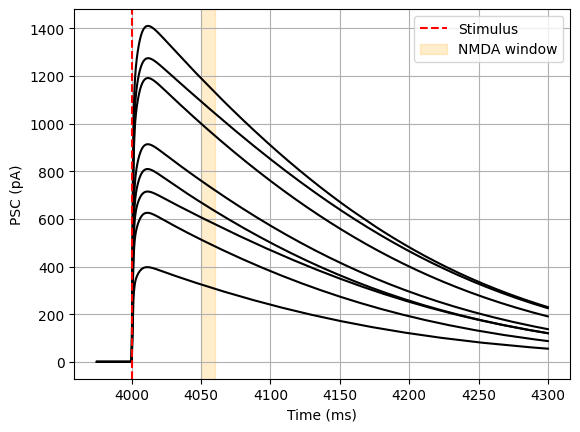

NMDA/AMPA ratio for 8 neurons: 0.2963944569384568 ± 0.09827370795469596


In [2]:
snudda_data_path = (
    "/Users/peirui/code_collection/BasalGangliaData/data"
)
rds = 123
ratio_list = [0.3,1,3,4,5]
nmda_config = "/Users/peirui/code_collection/treem/tutorials/syn_distribution/syn_config/msnd1-m1rh-ipsi.json"
v_hold_ampa = -81e-3 # -11mv liquid junction potential
v_hold_nmda = 29e-3 # -11mv liquid junction potential
simulation_time_nmda = 5
act_time_nmda = 4
simulation_time_ampa = 2
act_time_ampa = 1
num_inputs = 100
number_neurons = 8
output_path = "/Users/peirui/code_collection/treem/tutorials/syn_distribution/output_syn_distribution/"
Path(output_path).mkdir(parents=True, exist_ok=True)
neuron_path = "/Users/peirui/code_collection/BasalGangliaData/data/neurons/striatum/dspn/str-dspn-e150602_c1_D1-mWT-0728MSN01-v20220620"
result={}
for ratio in ratio_list:
    network_path_ampa = run_nmda_VC(snudda_data_path,rds,ratio,nmda_config,v_hold_ampa,"ampa",simulation_time_ampa,act_time_ampa,number_neurons, neuron_path, num_inputs)
    network_path_nmda = run_nmda_VC(snudda_data_path, rds,ratio,nmda_config,v_hold_nmda,"nmda",simulation_time_nmda,act_time_nmda,number_neurons, neuron_path, num_inputs)

    amp_list_ampa,preserve_id_ampa = collect_amp_data(network_path_ampa,"ampa",act_time_ampa,output_path,neuron_path,ratio, num_inputs,show_plot=True)
    amp_list_nmda, preserve_id_nmda = collect_amp_data(network_path_nmda,"nmda",act_time_nmda,output_path, neuron_path, ratio, num_inputs,show_plot=True)
    nmda_ampa_ratio = [amp_list_nmda[p] / amp_list_ampa[p] for p in preserve_id_nmda]
    result[ratio] = nmda_ampa_ratio
    print(f"NMDA/AMPA ratio for {len(nmda_ampa_ratio)} neurons: {np.mean(nmda_ampa_ratio)} ± {np.std(nmda_ampa_ratio)}")
with open(os.path.join(output_path, f"nmda_ampa_ratio_{ratio_list}_summary.json"), "w") as f:
    json.dump(result, f, indent=4)

Plot saved to: /Users/peirui/code_collection/treem/tutorials/syn_distribution/output_syn_distribution/ratio_scatter_mean_std.png


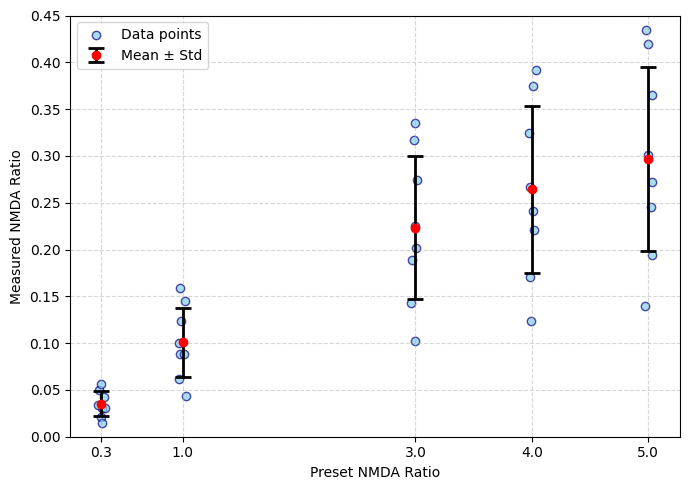

In [6]:
import json
import os
import re
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

def plot_scatter_mean_std(target_values, mode="ratio", save_path=None, y_limits=None):
    """
    Plots scatter points with mean ± std error bars for either 'ratio' or 'num_inputs'.
    """
    data_dict = result

    plt.figure(figsize=(7, 5))

    # Calculate dynamic jitter based on spacing between target values
    if len(target_values) > 1:
        jitter_range = (target_values[1] - target_values[0]) * 0.05
    else:
        jitter_range = 0.02

    for idx, val in enumerate(target_values):
        vals = np.array(data_dict.get(val, []))
        if len(vals) == 0:
            print(f"Warning: No data found for {mode} = {val}")
            continue

        mean_val = np.mean(vals)
        std_val = np.std(vals)

        # Add horizontal jitter
        jitter = np.random.uniform(-jitter_range, jitter_range, size=len(vals))
        x_positions = np.full_like(vals, val) + jitter

        # Scatter plot of individual values
        plt.scatter(
            x_positions, vals, alpha=0.7, color="skyblue", edgecolors="navy",
            label="Data points" if idx == 0 else ""
        )

        # Mean ± Std error bar
        plt.errorbar(
            val, mean_val, yerr=std_val,
            fmt="o", color="red", ecolor="black", elinewidth=2, capsize=6, capthick=2,
            label="Mean ± Std" if idx == 0 else ""
        )

    # Set x & y labels dynamically based on mode
    if mode == "ratio":
        plt.xlabel("Preset NMDA Ratio")
        plt.ylabel("Measured NMDA Ratio")
    else:
        plt.xlabel("Number of Inputs")
        plt.ylabel("Measured NMDA Ratio")

    if y_limits:
        plt.ylim(y_limits)

    plt.xticks(target_values)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300)
        print(f"Plot saved to: {save_path}")

    plt.show()




# # 1. Plot for Varying Number of Inputs
# plot_scatter_mean_std(
#     json_dir=output_path,
#     target_values=[25, 50, 75, 100],
#     mode="num_inputs",
#     save_path=os.path.join(output_path, "num_inputs_scatter_mean_std.png"),
#     y_limits=(0, 0.45)
# )

# 2. Plot for Varying Ratio
plot_scatter_mean_std(
    target_values=[0.3,1,3,4,5],
    mode="ratio",
    save_path=os.path.join(output_path, "ratio_scatter_mean_std.png"),
    y_limits=(0, 0.45)
)